# Análise exploratória: decisões sancionadoras da ANPD

**Disciplina:** Inteligência Artificial, Prof. Dr. Leandro Zerbinatti, 7ºJ SI Noite
**Integrante:** Mateus Ciancio, RA 10390145, 10390145@mackenzista.com.br

**Síntese:** análise exploratória dos 10 processos sancionadores publicados pela ANPD: metadados, qualidade dos dados, características dos documentos, vocabulário jurídico e, depois do gabarito, condutas e sanções. Figuras e números são gravados em `resultados/`.

**Histórico de alterações:**
- 03/11/2026, Mateus Ciancio, criação do notebook para a entrega N2

In [1]:
import json, os, re, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

RAIZ = Path(os.environ.get('PROJETO_RAIZ', Path.cwd().parent))
sys.path.insert(0, str(RAIZ / 'src'))
from comum import GABARITO, RESULTADOS, TEXTOS, canonizar_dispositivo, canonizar_sancao, normalizar_texto

FIG = RESULTADOS / 'figuras'
FIG.mkdir(parents=True, exist_ok=True)
AZUL, CINZA = '#2F6DA8', '#8A8F98'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight'})
eda = {}
fontes = pd.read_csv(RAIZ / 'dados' / 'fontes.csv', dtype=str)
documentos = pd.read_csv(RESULTADOS / 'documentos.csv')
processos = fontes.drop_duplicates('id').copy()
processos['ano_lista'] = processos.ano_lista.astype(int)

## 1. Universo e metadados

A página oficial lista 10 processos. O dataset é, portanto, um **censo** do que está publicado, não uma amostra.

In [2]:
eda['processos'] = len(processos)
eda['documentos'] = len(fontes)
eda['por_setor'] = processos.setor.value_counts().to_dict()
eda['por_ano'] = {int(k): int(v) for k, v in processos.ano_lista.value_counts().sort_index().items()}
pd.crosstab(processos.ano_lista, processos.setor, margins=True)

setor,Privado,Publico,All
ano_lista,,,
2023,1,3,4
2024,0,5,5
2026,1,0,1
All,2,8,10


## 2. Qualidade do dataset da N1

Mede quanto do dataset entregue no primeiro bimestre era informação pendente ou inferida. Isso justifica a reconstrução feita na N2.

In [3]:
n1 = pd.read_csv(RAIZ / 'dados' / 'legado_n1' / 'anpd_decisoes_sancionadoras.csv', dtype=str)
campos = ['motivo_resumido', 'artigo_lgpd_citado', 'tipo_sancao']
qualidade = pd.DataFrame({c: {
    'preenchido': int((~n1[c].str.contains('verificar|inferido|provavelmente|Em andamento|nao divulgado', case=False)).sum()),
    'pendente, inferido ou desatualizado': int(n1[c].str.contains('verificar|inferido|provavelmente|Em andamento|nao divulgado', case=False).sum())} for c in campos}).T
eda['qualidade_n1'] = qualidade.to_dict('index')
qualidade

,preenchido,"pendente, inferido ou desatualizado"
motivo_resumido,2,8
artigo_lgpd_citado,1,9
tipo_sancao,2,8


## 3. Características dos documentos

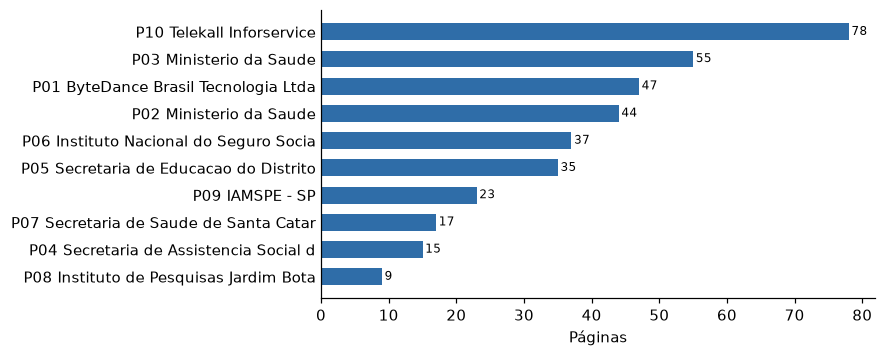

,id,tipo_doc,paginas,caracteres,caracteres_por_pagina,tem_camada_de_texto
0,P01,relatorio,42,147281,3506.7,True
1,P01,despacho,5,7123,1424.6,True
2,P02,relatorio,44,91626,2082.4,True
3,P03,relatorio,55,119344,2169.9,True
4,P04,relatorio,15,76202,5080.1,True
5,P05,relatorio,35,74259,2121.7,True
6,P06,relatorio,37,85060,2298.9,True
7,P07,relatorio,17,57464,3380.2,True
8,P08,relatorio,9,23876,2652.9,True
9,P09,relatorio,23,74426,3235.9,True


In [4]:
eda['paginas_total'] = int(documentos.paginas.sum())
eda['paginas_mediana'] = float(documentos.paginas.median())
eda['paginas_min'] = int(documentos.paginas.min())
eda['paginas_max'] = int(documentos.paginas.max())
eda['caracteres_total'] = int(documentos.caracteres.sum())
eda['digitalizados'] = documentos.loc[~documentos.tem_camada_de_texto, 'arquivo'].tolist()
paginas = documentos.groupby('id').paginas.sum().sort_values()
nomes = processos.set_index('id').entidade.str.slice(0, 34)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.barh([f'{i} {nomes[i]}' for i in paginas.index], paginas.values, color=AZUL, height=.62)
for y, v in enumerate(paginas.values):
    ax.text(v + .4, y, str(v), va='center', fontsize=8)
ax.set_xlabel('Páginas'); ax.grid(False); ax.tick_params(axis='y', length=0)
fig.savefig(FIG / 'fig1_paginas.png'); plt.show()
documentos[['id', 'tipo_doc', 'paginas', 'caracteres', 'caracteres_por_pagina', 'tem_camada_de_texto']]

## 4. Dispositivos mencionados

Conta menções a artigos no texto integral. A diferença entre os artigos **mencionados** aqui e os realmente **infringidos** no gabarito mostra por que a busca por palavra-chave não basta.

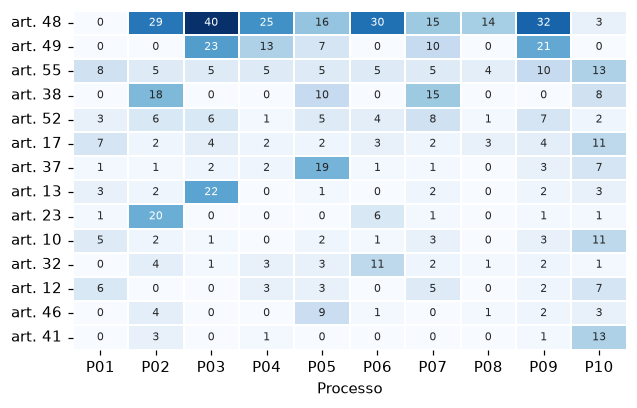

In [5]:
com_texto = documentos[documentos.tem_camada_de_texto]
textos = {}
for linha in com_texto.itertuples():
    bruto = (TEXTOS / f'{linha.arquivo[:-4]}.txt').read_text(encoding='utf-8')
    textos[linha.id] = textos.get(linha.id, '') + ' ' + re.sub(r'\[PAGINA \d+\]', ' ', bruto)
normal = {k: normalizar_texto(v) for k, v in textos.items()}
mencoes = pd.DataFrame({k: pd.Series(re.findall(r'art(?:igo)?s?\.?\s*(\d{1,2})\b', v)).value_counts() for k, v in normal.items()}).fillna(0).astype(int)
mencoes = mencoes.loc[mencoes.sum(axis=1).sort_values(ascending=False).index[:14]]
mencoes.index = [f'art. {i}' for i in mencoes.index]
eda['artigos_mais_mencionados'] = mencoes.sum(axis=1).head(5).to_dict()
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(mencoes, cmap='Blues', annot=True, fmt='d', annot_kws={'size': 7}, linewidths=1, linecolor='white', cbar=False, ax=ax)
ax.set_xlabel('Processo'); ax.set_ylabel('')
fig.savefig(FIG / 'fig2_mencoes.png'); plt.show()

## 5. Vocabulário e semelhança entre processos

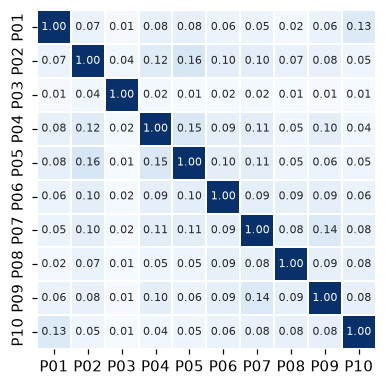

In [6]:
PARADAS = '''a o e de da do das dos em no na nos nas para por com sem que se um uma uns umas os as ao aos ou como mais menos foi foram ser sua seu suas seus este esta esse essa isso nao sao pela pelo pelas pelos entre sobre tambem ja ha art artigo lei anpd lgpd dados pessoais processo nº no pagina sei fls item itens deste desta dessa desse quanto'''.split()
ordem = sorted(normal)
vetor = TfidfVectorizer(stop_words=PARADAS, ngram_range=(1, 2), min_df=1, max_df=.85 if len(ordem) >= 3 else 1.0, token_pattern=r'(?u)\b[a-z]{4,}\b')
matriz = vetor.fit_transform([normal[k] for k in ordem])
termos = np.array(vetor.get_feature_names_out())
destaque = {k: termos[np.argsort(matriz[i].toarray()[0])[::-1][:6]].tolist() for i, k in enumerate(ordem)}
similaridade = pd.DataFrame(cosine_similarity(matriz), index=ordem, columns=ordem)
fora_diagonal = similaridade.values[np.triu_indices(len(ordem), 1)]
eda['similaridade_media'] = round(float(fora_diagonal.mean()), 3) if len(fora_diagonal) else None
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(similaridade, cmap='Blues', vmin=0, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=1, linecolor='white', cbar=False, square=True, ax=ax)
fig.savefig(FIG / 'fig3_similaridade.png'); plt.show()
# Os termos de maior TF-IDF nao sao exibidos: incluiam nomes de pessoas fisicas citados nos autos.

## 6. Condutas e sanções (gabarito humano)

Esta parte só roda quando o gabarito estiver concluído.

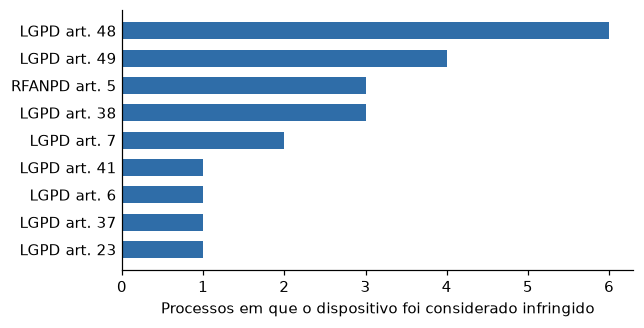

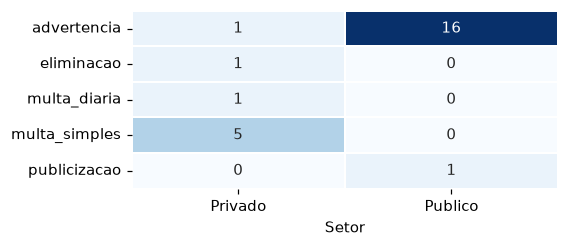

In [7]:
gabarito_pronto = False
if GABARITO.exists():
    sancoes = pd.read_excel(GABARITO, sheet_name='sancoes', dtype=str).fillna('')
    sancoes = sancoes[sancoes.id.str.strip() != ''].copy()
    gabarito_pronto = len(sancoes) > 0
if gabarito_pronto:
    sancoes['artigo'] = sancoes.dispositivo.map(lambda v: canonizar_dispositivo(v)[0].replace(' art', ' art. '))
    sancoes['sancao'] = sancoes.tipo_sancao.map(canonizar_sancao)
    sancoes = sancoes.merge(processos[['id', 'setor']], on='id')
    eda['linhas_gabarito'] = len(sancoes)
    eda['dispositivos_por_processo_media'] = round(sancoes.groupby('id').artigo.nunique().mean(), 2)
    eda['artigos_infringidos'] = sancoes.drop_duplicates(['id', 'artigo']).artigo.value_counts().to_dict()
    eda['sancoes_por_setor'] = pd.crosstab(sancoes.sancao, sancoes.setor).to_dict('index')
    eda['medida_corretiva'] = sancoes.medida_corretiva.value_counts().to_dict()
    multas = pd.to_numeric(sancoes.valor_reais.str.replace(',', '.'), errors='coerce').groupby(sancoes.id).sum()
    eda['multa_por_processo'] = {k: float(v) for k, v in multas[multas > 0].items()}
    contagem = sancoes.drop_duplicates(['id', 'artigo']).artigo.value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(6, max(2.2, .34 * len(contagem))))
    ax.barh(contagem.index, contagem.values, color=AZUL, height=.62)
    ax.set_xlabel('Processos em que o dispositivo foi considerado infringido')
    ax.xaxis.get_major_locator().set_params(integer=True); ax.tick_params(axis='y', length=0)
    fig.savefig(FIG / 'fig4_dispositivos.png'); plt.show()
    tabela = pd.crosstab(sancoes.sancao, sancoes.setor)
    fig, ax = plt.subplots(figsize=(5, max(2, .42 * len(tabela))))
    sns.heatmap(tabela, cmap='Blues', annot=True, fmt='d', linewidths=1, linecolor='white', cbar=False, ax=ax)
    ax.set_xlabel('Setor'); ax.set_ylabel('')
    fig.savefig(FIG / 'fig5_sancoes.png'); plt.show()
else:
    print('Gabarito ainda vazio: seção ignorada.')

In [8]:
(RESULTADOS / 'eda.json').write_text(json.dumps(eda, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
print(json.dumps(eda, ensure_ascii=False, indent=2, default=str)[:1500])

{
  "processos": 10,
  "documentos": 11,
  "por_setor": {
    "Publico": 8,
    "Privado": 2
  },
  "por_ano": {
    "2023": 4,
    "2024": 5,
    "2026": 1
  },
  "qualidade_n1": {
    "motivo_resumido": {
      "preenchido": 2,
      "pendente, inferido ou desatualizado": 8
    },
    "artigo_lgpd_citado": {
      "preenchido": 1,
      "pendente, inferido ou desatualizado": 9
    },
    "tipo_sancao": {
      "preenchido": 2,
      "pendente, inferido ou desatualizado": 8
    }
  },
  "paginas_total": 360,
  "paginas_mediana": 35.0,
  "paginas_min": 5,
  "paginas_max": 78,
  "caracteres_total": 909149,
  "digitalizados": [],
  "artigos_mais_mencionados": {
    "art. 48": 204,
    "art. 49": 74,
    "art. 55": 65,
    "art. 38": 51,
    "art. 52": 43
  },
  "similaridade_media": 0.071,
  "linhas_gabarito": 25,
  "dispositivos_por_processo_media": 2.44,
  "artigos_infringidos": {
    "LGPD art. 48": 6,
    "LGPD art. 49": 4,
    "LGPD art. 38": 3,
    "RFANPD art. 5": 3,
    "LGPD art